## Data Collection & EDA

## 1) Dataset loading

In [29]:
#Importing required library 

#this is used for Access dataset files
import os
from pathlib import Path

#analysing the dataset 
import numpy as np
import pandas as pd

#visualisation 
import matplotlib.pyplot as plt
import seaborn as sns

# Read MRI images
from PIL import Image

# Deep learning
import tensorflow as tf

In [8]:
# Project dataset paths
DATASET_DIR = Path("../dataset")

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Training directory exists: True
Testing directory exists: True


In [12]:
image_extensions = {".jpg", ".jpeg", ".png"}
training_images = [file for file in TRAIN_DIR.rglob("*")if file.suffix.lower() in image_extensions]
testing_images = [file for file in TEST_DIR.rglob("*")if file.suffix.lower() in image_extensions]

print("Training images:", len(training_images))
print("Testing images:", len(testing_images))
print("Total images:", len(training_images) + len(testing_images))

Training images: 5600
Testing images: 1600
Total images: 7200


## 2 Understanding Folder Structure

In [ ]:
# Understanding dataset folder structure

for split in ["Training", "Testing"]:
    split_path = DATASET_DIR / split
    print(f"\n{split} folder:")
    for class_folder in sorted(split_path.iterdir()):
        if class_folder.is_dir(): 
            print(f"    {class_folder.name}/")


Training folder:
    glioma/
    meningioma/
    notumor/
    pituitary/

Testing folder:
    glioma/
    meningioma/
    notumor/
    pituitary/


In [16]:
# Count images class-wise

for split_name, split_path in [("Training", TRAIN_DIR),("Testing", TEST_DIR)]:
    print(f"\n{split_name} Dataset")
    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name
        if class_path.is_dir():
            images = [file for file in class_path.iterdir() if file.suffix.lower() in image_extensions]
            print(f"{class_name}: {len(images)} images")


Training Dataset
glioma: 1400 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images

Testing Dataset
glioma: 400 images
meningioma: 400 images
notumor: 400 images
pituitary: 400 images


## 3 Image Visualization

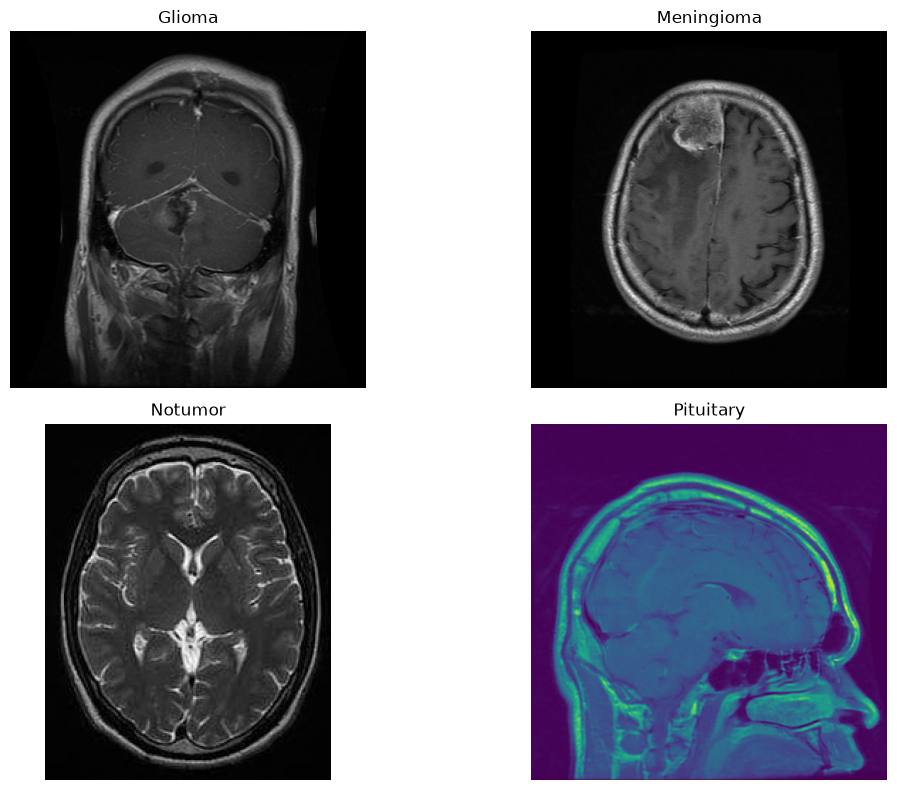

In [19]:
import random 
classes = ["glioma", "meningioma", "notumor", "pituitary"]

plt.figure(figsize=(12, 8))
for i, class_name in enumerate(classes):

    class_path = TRAIN_DIR / class_name
    image_files = [file for file in class_path.iterdir() if file.suffix.lower() in image_extensions]

    image_path = random.choice(image_files)
    img = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
sample_path = random.choice(training_images)

img = Image.open(sample_path)
print("Image path:", sample_path)
print("Image format:", img.format)
print("Image size:", img.size)
print("Image mode:", img.mode)

Image path: ..\dataset\Training\glioma\Tr-gl_109.jpg
Image format: JPEG
Image size: (512, 512)
Image mode: L


## 4 Class Distribution Analysis

In [26]:
# Store class-wise image counts
classes = ["glioma", "meningioma", "notumor", "pituitary"]
distribution = []

for class_name in classes:
    train_count = len(list((TRAIN_DIR / class_name).glob("*")))
    test_count = len(list((TEST_DIR / class_name).glob("*")))

    distribution.append({"Class": class_name,"Training": train_count,"Testing": test_count,"Total": train_count + test_count})

df_distribution = pd.DataFrame(distribution)
df_distribution

,Class,Training,Testing,Total
0,glioma,1400,400,1800
1,meningioma,1400,400,1800
2,notumor,1400,400,1800
3,pituitary,1400,400,1800


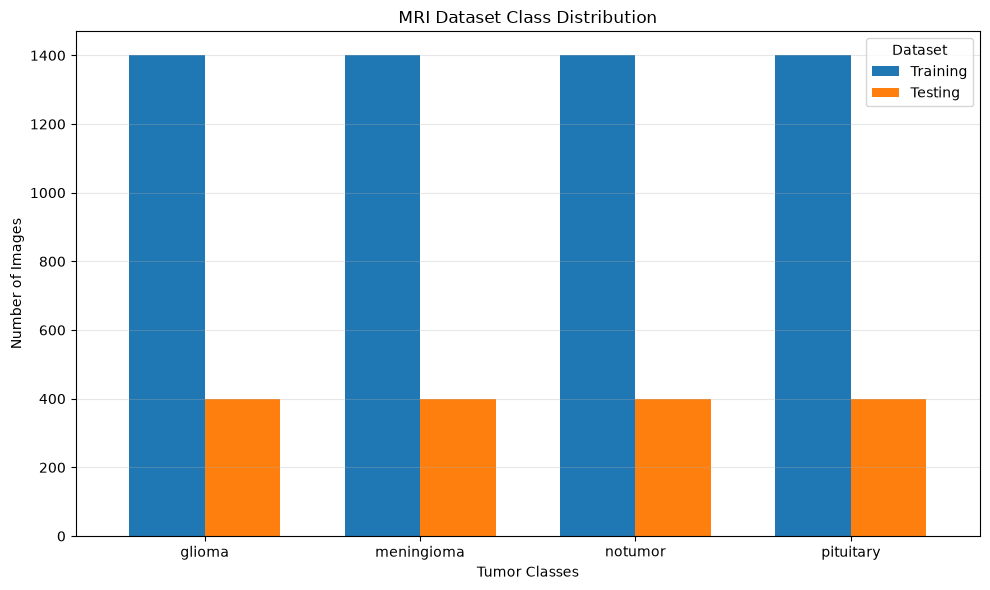

In [ ]:
# Plot class distribution

df_plot = df_distribution.set_index("Class")[["Training", "Testing"]]

df_plot.plot(kind="bar",figsize=(10, 6),width=0.7)

plt.title("MRI Dataset Class Distribution")
plt.xlabel("Tumor Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate percentage distribution

df_distribution["Percentage"] = (df_distribution["Total"] /df_distribution["Total"].sum()) * 100
df_distribution

,Class,Training,Testing,Total,Percentage
0,glioma,1400,400,1800,25.0
1,meningioma,1400,400,1800,25.0
2,notumor,1400,400,1800,25.0
3,pituitary,1400,400,1800,25.0


## 5 Data Quality Checks

In [30]:
# Check image files for corruption
corrupted_images = []
all_images = training_images + testing_images

for image_path in all_images:
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_path)

print("Total images checked:", len(all_images))
print("Corrupted images:", len(corrupted_images))

Total images checked: 7200
Corrupted images: 0


In [ ]:
# Inspect image dimensions and formats
image_info = []
for image_path in all_images:
    with Image.open(image_path) as img:
        image_info.append({
            "Image": image_path.name,
            "Width": img.width,
            "Height": img.height,
            "Format": img.format,
            "Mode": img.mode})

df_image_info = pd.DataFrame(image_info)
df_image_info.head()

,Image,Width,Height,Format,Mode
0,Tr-gl_1.jpg,512,512,JPEG,L
1,Tr-gl_10.jpg,512,512,JPEG,L
2,Tr-gl_100.jpg,512,512,JPEG,L
3,Tr-gl_1000.jpg,512,512,JPEG,L
4,Tr-gl_1001.jpg,512,512,JPEG,L


In [ ]:
print("Image formats:")
print(df_image_info["Format"].value_counts())

print("\nImage modes:")
print(df_image_info["Mode"].value_counts())

print("\nImage dimensions:")
print(df_image_info.groupby(["Width", "Height"]).size().sort_values(ascending=False).head(10))

Image formats:
Format
JPEG    7196
PNG        4
Name: count, dtype: int64

Image modes:
Mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64

Image dimensions:
Width  Height
512    512       5014
225    225        338
630    630         90
201    251         57
228    221         51
232    217         50
236    236         48
442    442         48
150    198         44
200    252         43
dtype: int64


In [ ]:
import hashlib
from collections import Counter

def calculate_hash(image_path):
    hasher = hashlib.md5()
    with open(image_path, "rb") as file:
        hasher.update(file.read())

    return hasher.hexdigest()

image_hashes = [calculate_hash(path) for path in all_images]
hash_counts = Counter(image_hashes)
duplicate_groups = {image_hash: count for image_hash, count in hash_counts.items() if count > 1}

print("Unique image contents:", len(hash_counts))
print("Duplicate content groups:", len(duplicate_groups))
print("Files belonging to duplicate groups:", sum(duplicate_groups.values()))

Unique image contents: 7013
Duplicate content groups: 153
Files belonging to duplicate groups: 340


In [35]:
# Map each hash to its dataset location

hash_locations = {}
for path in all_images:
    image_hash = calculate_hash(path)
    hash_locations.setdefault(image_hash, []).append(path)

# Find hashes appearing in both datasets
cross_split_duplicates = {}
for image_hash, paths in hash_locations.items():
    splits = {path.parts[-3] for path in paths}
    if "Training" in splits and "Testing" in splits:
        cross_split_duplicates[image_hash] = paths

print("Duplicates across Training and Testing:",len(cross_split_duplicates))

Duplicates across Training and Testing: 0


In [37]:
for image_hash, paths in list(cross_split_duplicates.items())[:5]:
    print("\nDuplicate hash:", image_hash)
    for path in paths:
        print(path)